# Chapter 10: Clustering Techniques

This notebook covers Chapter 10 of *scikit-learn Cookbook* (3rd Edition, Packt). **Clustering** is an unsupervised learning task: the goal is to group similar data points together without using any labels. It is used for customer segmentation, grouping documents, image compression, and exploring the structure of new datasets.

**Topics covered:**
- K-Means clustering and the k-means++ initialization
- Choosing the number of clusters: elbow method and silhouette analysis
- Mini-Batch K-Means for large datasets
- Hierarchical (agglomerative) clustering and dendrograms
- Density-based clustering: DBSCAN and HDBSCAN
- Gaussian Mixture Models for soft clustering
- Evaluating clusters with internal and external metrics
- Comparing algorithms on clusters of different shapes

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import make_blobs, make_moons, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (KMeans, MiniBatchKMeans, AgglomerativeClustering,
                             DBSCAN, HDBSCAN)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import dendrogram, linkage

## 1. K-Means Clustering

**K-Means** divides the data into $K$ clusters by minimizing the **inertia**, the sum of squared distances from each point to the center (centroid) of its cluster:

$$\text{inertia} = \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in C_k} \|\mathbf{x}_i - \boldsymbol{\mu}_k\|^2$$

The algorithm repeats two steps until the centroids stop moving:
1. **Assign** each point to the nearest centroid.
2. **Update** each centroid to the mean of its assigned points.

K-Means can end in a poor solution depending on where the centroids start. scikit-learn uses **k-means++** initialization (starting centroids spread far apart) and runs the algorithm several times (`n_init`), keeping the best result.

The example uses synthetic data with 4 groups.

Inertia: 745.13
Iterations until convergence: 2
Points per cluster: [125 125 125 125]


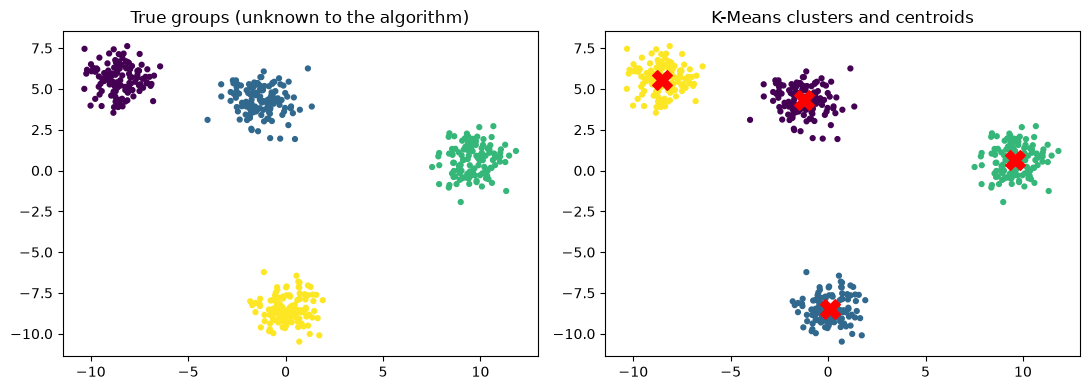

In [2]:
X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=0.9, random_state=7)

kmeans = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42)
labels = kmeans.fit_predict(X)

print('Inertia:', round(kmeans.inertia_, 2))
print('Iterations until convergence:', kmeans.n_iter_)
print('Points per cluster:', np.bincount(labels))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X[:, 0], X[:, 1], c=y_true, cmap='viridis', s=12)
axes[0].set_title('True groups (unknown to the algorithm)')
axes[1].scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=12)
axes[1].scatter(*kmeans.cluster_centers_.T, c='red', marker='X', s=200)
axes[1].set_title('K-Means clusters and centroids')
plt.tight_layout()
plt.show()

K-Means recovers the four groups almost perfectly, with each centroid (red X) in the middle of a group. The cluster numbers may differ from the true group numbers, because cluster labels are arbitrary names.

## 2. Choosing the Number of Clusters

In real problems $K$ is unknown. Two common tools:
- **Elbow method**: plot inertia against $K$. Inertia always decreases as $K$ grows, but the decrease slows sharply after the "right" number, forming an elbow.
- **Silhouette score**: for each point, compares $a$ (average distance to points in its own cluster) with $b$ (average distance to points in the nearest other cluster):

$$s = \frac{b - a}{\max(a, b)}$$

Values near 1 mean the point is well inside its cluster, near 0 means it is on a boundary, and negative values suggest it is in the wrong cluster. The mean silhouette over all points is used to compare values of $K$.

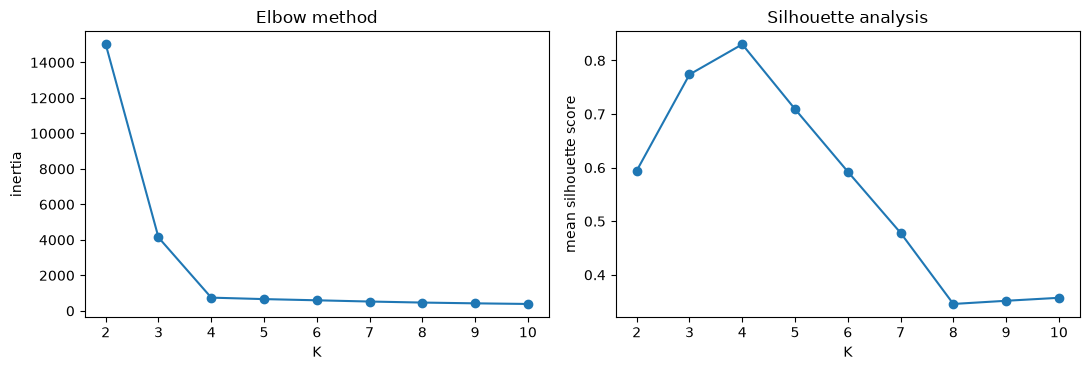

Best K by silhouette: 4


In [3]:
k_values = range(2, 11)
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k_values, inertias, marker='o')
axes[0].set_xlabel('K')
axes[0].set_ylabel('inertia')
axes[0].set_title('Elbow method')
axes[1].plot(k_values, silhouettes, marker='o')
axes[1].set_xlabel('K')
axes[1].set_ylabel('mean silhouette score')
axes[1].set_title('Silhouette analysis')
plt.tight_layout()
plt.show()

print('Best K by silhouette:', list(k_values)[int(np.argmax(silhouettes))])

The inertia curve drops steeply up to $K = 4$ and then flattens, and the silhouette score peaks at the same value. Both methods agree with the true structure of the data. In real data the two methods do not always agree, so they are used together with domain knowledge.

### 2.1 Silhouette Plot

A silhouette plot shows the score of every point, grouped by cluster. Clusters of similar width with few negative values indicate a good clustering.

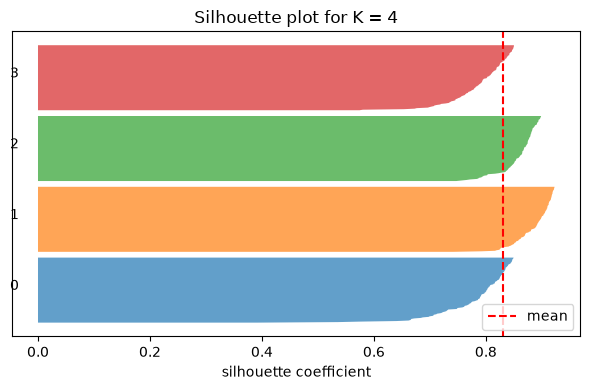

In [4]:
sample_sil = silhouette_samples(X, labels)

fig, ax = plt.subplots(figsize=(6, 4))
y_lower = 0
for k in range(4):
    vals = np.sort(sample_sil[labels == k])
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, alpha=0.7)
    ax.text(-0.05, y_lower + len(vals) / 2, str(k))
    y_lower += len(vals) + 10
ax.axvline(sample_sil.mean(), color='red', linestyle='--', label='mean')
ax.set_xlabel('silhouette coefficient')
ax.set_yticks([])
ax.legend()
ax.set_title('Silhouette plot for K = 4')
plt.tight_layout()
plt.show()

All four clusters have mostly high silhouette values and are of similar size, confirming that the clustering is well separated.

## 3. Mini-Batch K-Means

Standard K-Means uses all points in every iteration, which becomes slow for very large datasets. **Mini-Batch K-Means** updates the centroids using small random batches of data. It is much faster and uses less memory, with only a small loss in quality.

In [5]:
X_big, _ = make_blobs(n_samples=200_000, centers=5, random_state=0)

for name, model in [('KMeans', KMeans(n_clusters=5, n_init=3, random_state=0)),
                    ('MiniBatchKMeans', MiniBatchKMeans(n_clusters=5, batch_size=2048,
                                                        n_init=3, random_state=0))]:
    start = time.perf_counter()
    model.fit(X_big)
    print(f'{name:>16}: {time.perf_counter() - start:.2f} s, inertia = {model.inertia_:,.0f}')

          KMeans: 0.14 s, inertia = 366,536
 MiniBatchKMeans: 1.59 s, inertia = 366,605


Mini-Batch K-Means is noticeably faster while reaching an inertia close to standard K-Means, which makes it the practical choice when the dataset is very large or arrives in streams.

## 4. Hierarchical (Agglomerative) Clustering

**Agglomerative clustering** starts with every point as its own cluster and repeatedly **merges the two closest clusters** until the desired number remains. The **linkage** criterion defines the distance between clusters:
- **Ward**: merges the pair that increases total within-cluster variance the least (similar spirit to K-Means).
- **Complete**: distance between the farthest points of two clusters.
- **Average**: average distance between all pairs of points.
- **Single**: distance between the closest points (can follow chain-like shapes).

The full sequence of merges can be drawn as a **dendrogram**, where cutting the tree at a certain height gives a number of clusters.

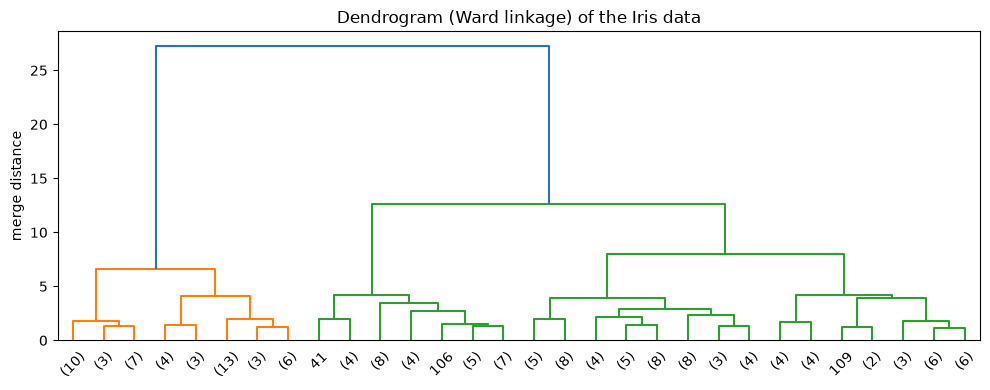

In [6]:
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

Z = linkage(X_iris, method='ward')
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=30, ax=ax)
ax.set_title('Dendrogram (Ward linkage) of the Iris data')
ax.set_ylabel('merge distance')
plt.tight_layout()
plt.show()

In [7]:
for link in ['ward', 'complete', 'average', 'single']:
    agg = AgglomerativeClustering(n_clusters=3, linkage=link).fit(X_iris)
    ari = adjusted_rand_score(iris.target, agg.labels_)
    print(f'{link:>8} linkage: cluster sizes = {np.bincount(agg.labels_)}, '
          f'ARI vs. true species = {ari:.3f}')

    ward linkage: cluster sizes = [71 49 30], ARI vs. true species = 0.615
complete linkage: cluster sizes = [77 49 24], ARI vs. true species = 0.573
 average linkage: cluster sizes = [50 97  3], ARI vs. true species = 0.562
  single linkage: cluster sizes = [100   1  49], ARI vs. true species = 0.558


The dendrogram shows a large jump in merge distance near the top, suggesting two or three natural groups. With three clusters, Ward linkage matches the true iris species best. Single linkage tends to create one huge cluster plus tiny ones (the "chaining" effect), which shows how strongly the linkage choice affects the result.

## 5. Density-Based Clustering: DBSCAN

K-Means assumes round clusters of similar size. **DBSCAN** instead defines clusters as **dense regions** separated by sparse areas:
- `eps`: the radius of a neighborhood.
- `min_samples`: the minimum number of points within `eps` for a point to be a **core point**.

Points reachable from core points form a cluster, and points in sparse areas are labeled **noise** (label $-1$). DBSCAN finds clusters of **any shape**, does not need the number of clusters, and detects outliers. A common way to choose `eps` is the **k-distance plot**: sort each point's distance to its $k$-th nearest neighbor and look for the elbow.

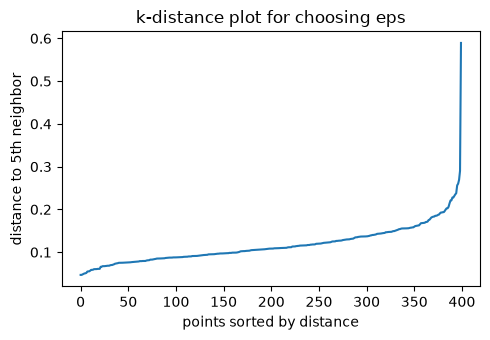

In [8]:
X_moon, y_moon = make_moons(n_samples=400, noise=0.07, random_state=42)
X_moon = StandardScaler().fit_transform(X_moon)

k = 5
dist, _ = NearestNeighbors(n_neighbors=k).fit(X_moon).kneighbors(X_moon)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(np.sort(dist[:, -1]))
ax.set_xlabel('points sorted by distance')
ax.set_ylabel(f'distance to {k}th neighbor')
ax.set_title('k-distance plot for choosing eps')
plt.tight_layout()
plt.show()

DBSCAN clusters found: 2
DBSCAN noise points: 1


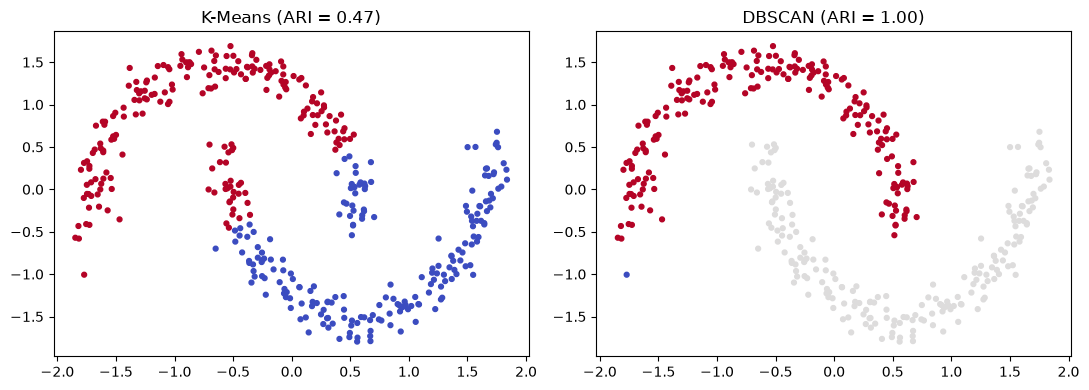

In [9]:
db = DBSCAN(eps=0.3, min_samples=5).fit(X_moon)
km_moon = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_moon)

print('DBSCAN clusters found:', len(set(db.labels_)) - (1 if -1 in db.labels_ else 0))
print('DBSCAN noise points:', int((db.labels_ == -1).sum()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X_moon[:, 0], X_moon[:, 1], c=km_moon.labels_, cmap='coolwarm', s=12)
axes[0].set_title(f'K-Means (ARI = {adjusted_rand_score(y_moon, km_moon.labels_):.2f})')
axes[1].scatter(X_moon[:, 0], X_moon[:, 1], c=db.labels_, cmap='coolwarm', s=12)
axes[1].set_title(f'DBSCAN (ARI = {adjusted_rand_score(y_moon, db.labels_):.2f})')
plt.tight_layout()
plt.show()

The k-distance curve bends upward around the chosen `eps`. K-Means cuts the two moons with a straight boundary because it looks for round clusters, while DBSCAN follows the curved shapes and separates the moons correctly, as the much higher Adjusted Rand Index shows.

### 5.1 HDBSCAN

DBSCAN uses a single `eps`, so it struggles when clusters have **different densities**. **HDBSCAN** (Hierarchical DBSCAN) builds a hierarchy of density levels and selects the most stable clusters, so it needs mainly `min_cluster_size` and adapts to varying density.

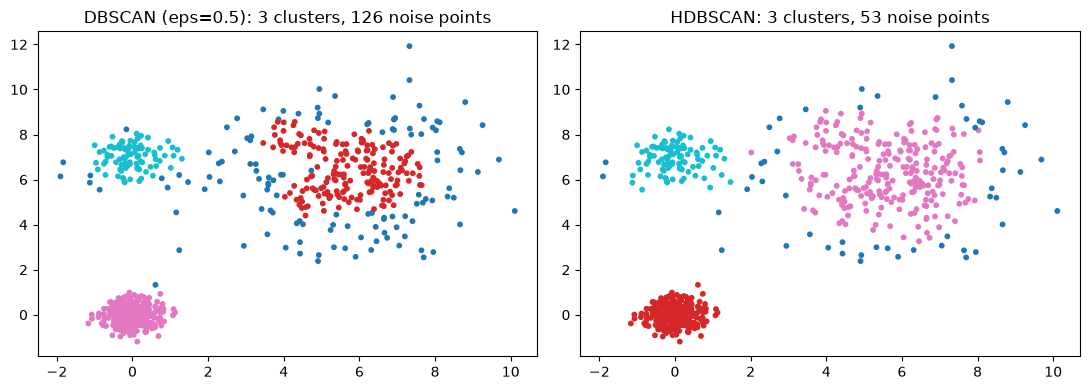

In [10]:
X_var, y_var = make_blobs(n_samples=[300, 300, 100], centers=[[0, 0], [6, 6], [0, 7]],
                          cluster_std=[0.4, 1.6, 0.6], random_state=3)

results = {
    'DBSCAN (eps=0.5)': DBSCAN(eps=0.5, min_samples=10).fit_predict(X_var),
    'HDBSCAN': HDBSCAN(min_cluster_size=20).fit_predict(X_var),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, lab) in zip(axes, results.items()):
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    ax.scatter(X_var[:, 0], X_var[:, 1], c=lab, cmap='tab10', s=10)
    ax.set_title(f'{name}: {n_clusters} clusters, {(lab == -1).sum()} noise points')
plt.tight_layout()
plt.show()

With a single `eps`, DBSCAN treats much of the spread-out cluster as noise. HDBSCAN adapts to each cluster's density and recovers all three groups with far fewer points labeled as noise.

## 6. Gaussian Mixture Models (Soft Clustering)

A **Gaussian Mixture Model (GMM)** assumes the data comes from a mix of $K$ Gaussian (normal) distributions, each with its own mean and covariance:

$$p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

It is fitted with the **Expectation-Maximization (EM)** algorithm. Unlike K-Means, a GMM:
- gives **soft assignments**: a probability of belonging to each cluster,
- can model **elongated (elliptical)** clusters through the covariance matrices.

The number of components can be chosen with the **BIC** (Bayesian Information Criterion), where lower is better.

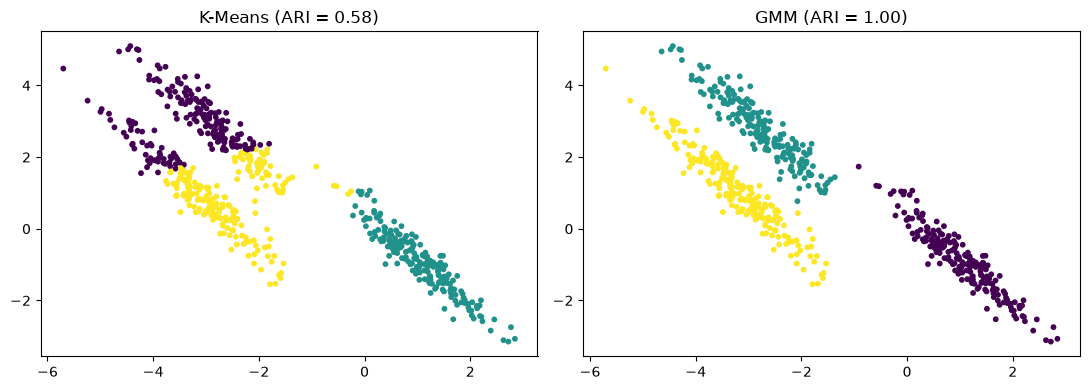

Soft assignments (first 3 points):
[[0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


In [11]:
rng = np.random.default_rng(0)
X_ell, y_ell = make_blobs(n_samples=600, centers=3, random_state=170)
X_ell = X_ell @ np.array([[0.6, -0.6], [-0.4, 0.8]])

km_ell = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_ell)
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42).fit(X_ell)
gmm_labels = gmm.predict(X_ell)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X_ell[:, 0], X_ell[:, 1], c=km_ell.labels_, cmap='viridis', s=10)
axes[0].set_title(f'K-Means (ARI = {adjusted_rand_score(y_ell, km_ell.labels_):.2f})')
axes[1].scatter(X_ell[:, 0], X_ell[:, 1], c=gmm_labels, cmap='viridis', s=10)
axes[1].set_title(f'GMM (ARI = {adjusted_rand_score(y_ell, gmm_labels):.2f})')
plt.tight_layout()
plt.show()

print('Soft assignments (first 3 points):')
print(gmm.predict_proba(X_ell[:3]).round(3))

In [12]:
bics = [GaussianMixture(n_components=k, random_state=42).fit(X_ell).bic(X_ell)
        for k in range(1, 8)]
print('BIC for 1 to 7 components:', np.round(bics, 0))
print('Best number of components by BIC:', int(np.argmin(bics)) + 1)

BIC for 1 to 7 components: [4273. 3509. 3062. 3093. 3121. 3163. 3184.]
Best number of components by BIC: 3


The stretched clusters are a problem for K-Means, which assumes round groups, while the GMM fits ellipses and matches the true groups much better. `predict_proba` gives each point a probability for every cluster, which is useful for points near boundaries. The BIC reaches its minimum at three components, matching the true structure.

## 7. Evaluating Clusters

**Internal metrics** need no labels and judge compactness and separation:
- **Silhouette score**: higher is better, range $[-1, 1]$.
- **Calinski-Harabasz index**: ratio of between-cluster to within-cluster dispersion; higher is better.
- **Davies-Bouldin index**: average similarity between each cluster and its most similar one; lower is better.

**External metrics** compare with known labels, when they exist:
- **Adjusted Rand Index (ARI)**: agreement between two labelings, corrected for chance (1 = perfect, about 0 = random).
- **Normalized Mutual Information (NMI)**: shared information between labelings, from 0 to 1.

In [13]:
models = {
    'K-Means': KMeans(n_clusters=3, n_init=10, random_state=42),
    'Agglomerative (ward)': AgglomerativeClustering(n_clusters=3),
    'GMM': GaussianMixture(n_components=3, random_state=42),
}
rows = []
for name, m in models.items():
    lab = m.fit_predict(X_iris)
    rows.append({
        'model': name,
        'silhouette': silhouette_score(X_iris, lab),
        'calinski_harabasz': calinski_harabasz_score(X_iris, lab),
        'davies_bouldin': davies_bouldin_score(X_iris, lab),
        'ARI': adjusted_rand_score(iris.target, lab),
        'NMI': normalized_mutual_info_score(iris.target, lab),
    })
pd.DataFrame(rows).set_index('model').round(3)

,silhouette,calinski_harabasz,davies_bouldin,ARI,NMI
model,,,,,
K-Means,0.460,241.904,0.834,0.620,0.659
Agglomerative (ward),0.447,222.719,0.803,0.615,0.675
GMM,0.475,141.231,0.887,0.516,0.657


The internal and external metrics do not always rank the models the same way. A model can have well-separated clusters (good silhouette) that still do not match the true species, because two iris species overlap in the feature space. This is why clustering results should be checked with several metrics and with domain knowledge.

## Chapter Summary

- **K-Means** minimizes inertia using k-means++ initialization and multiple restarts; it works best for round, similar-sized clusters.
- The number of clusters can be chosen with the **elbow method** and **silhouette analysis**.
- **Mini-Batch K-Means** trades a little accuracy for large gains in speed on big datasets.
- **Agglomerative clustering** builds a hierarchy of merges, visualized with a **dendrogram**; the **linkage** choice strongly affects the result.
- **DBSCAN** finds clusters of any shape and labels noise, using `eps` and `min_samples`; **HDBSCAN** handles clusters with different densities.
- **Gaussian Mixture Models** provide soft, probabilistic assignments and elliptical clusters; the **BIC** helps choose the number of components.
- Clusters are evaluated with **internal metrics** (silhouette, Calinski-Harabasz, Davies-Bouldin) and, when labels exist, **external metrics** (ARI, NMI).